# KMeans

In [1]:
import numpy as np
import PIL
from pathlib import Path
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs

In [4]:
# extra code – the exact arguments of make_blobs() are not important
blob_centers = np.array([[ 0.2,  2.3], [-1.5 ,  2.3], [-2.8,  1.8],
                         [-2.8,  2.8], [-2.8,  1.3]])
blob_std = np.array([0.4, 0.3, 0.1, 0.1, 0.1])
X, y = make_blobs(n_samples=2000, centers=blob_centers, cluster_std=blob_std,
                  random_state=7) # note that, y contains the cluster IDs, but we will not use them; that's what we want to predict

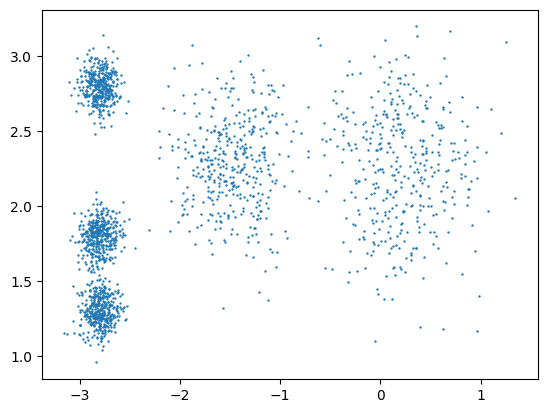

In [20]:
plt.scatter(X[:,0],X[:,1],s=0.5)
# plt.scatter(X[:,0],X[:,1],s=0.5,c=y)
plt.show()

In [12]:
unique = []
for i in y:
    if i not in unique:
        unique.append(i)
print(unique)

[np.int64(4), np.int64(2), np.int64(0), np.int64(1), np.int64(3)]


In [25]:
k = 5
kmeans = KMeans(n_clusters=5,random_state=42)
y_pred = kmeans.fit_predict(X)

In [26]:
y_pred

array([2, 2, 4, ..., 1, 4, 2], shape=(2000,), dtype=int32)

In [16]:
unique = []
for i in y_pred:
    if i not in unique:
        unique.append(i)
print(unique)

[np.int32(0), np.int32(4), np.int32(2), np.int32(3), np.int32(1)]


In [22]:
kmeans.labels_

array([0, 0, 4, ..., 3, 1, 0], shape=(2000,), dtype=int32)

In [17]:
y_pred is kmeans.labels_

True

In [18]:
kmeans.cluster_centers_

array([[-2.80214068,  1.55162671],
       [ 0.08703534,  2.58438091],
       [-1.46869323,  2.28214236],
       [-2.79290307,  2.79641063],
       [ 0.31332823,  1.96822352]])

In [27]:
X_new = np.array([[0, 2], [3, 2], [-3, 3], [-3, 2.5]])
kmeans.predict(X_new)

array([0, 4, 1, 1], dtype=int32)

In [34]:
# In KMeans class, the transform() method measures the distance from each instance to every centroid
kmeans.transform(X_new).round(2)

array([[2.9 , 2.81, 2.89, 1.49, 0.33],
       [5.85, 5.81, 5.84, 4.48, 2.8 ],
       [0.29, 1.21, 1.71, 1.69, 3.29],
       [0.36, 0.73, 1.22, 1.55, 3.22]])

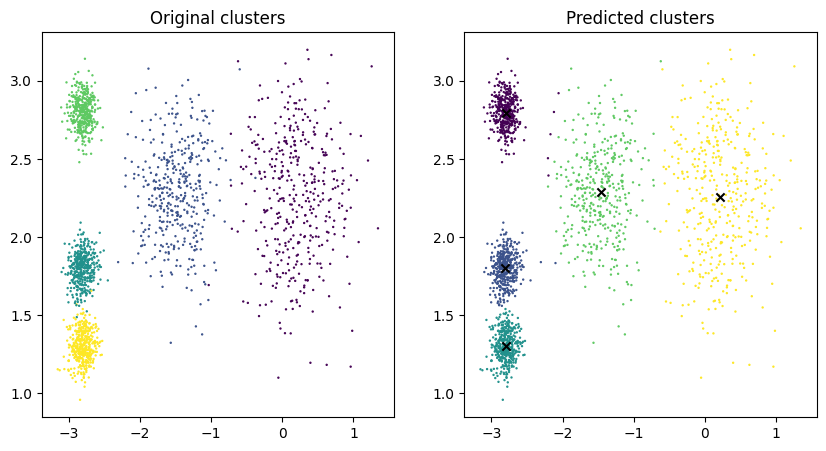

In [32]:
# plot
plt.figure(figsize=(10,5))
plt.subplot(1,2,1)
plt.scatter(X[:,0],X[:,1],s=0.5,c=y)
plt.title("Original clusters")

plt.subplot(1,2,2)
#plot data
plt.scatter(X[:,0],X[:,1],s=0.5,c=y_pred)
# plot centers
plt.scatter(kmeans.cluster_centers_[:,0],kmeans.cluster_centers_[:,1],marker='x', s=35,c="black")
plt.title("Predicted clusters")
plt.show()

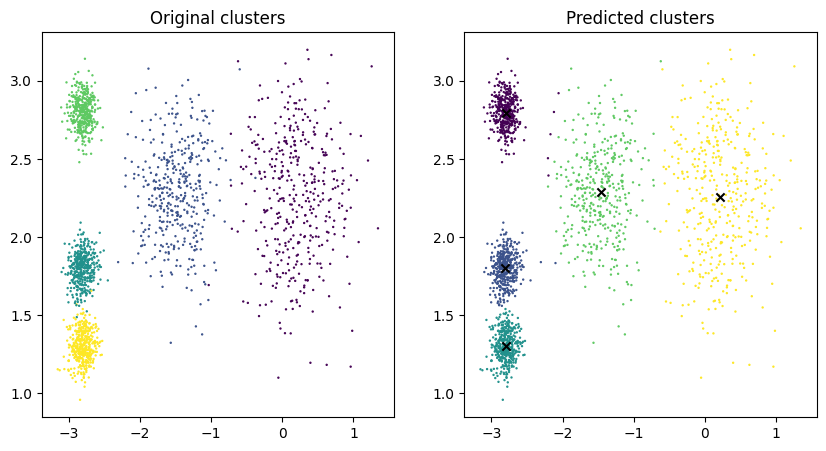

In [33]:
good_init = np.array([[-3, 3], [-3, 2], [-3, 1], [-1, 2], [0, 2]])
kmeans = KMeans(n_clusters=5, init=good_init, n_init=1, random_state=42)
y_pred = kmeans.fit_predict(X)

plt.figure(figsize=(10,5))
plt.subplot(1,2,1)
plt.scatter(X[:,0],X[:,1],s=0.5,c=y)
plt.title("Original clusters")

plt.subplot(1,2,2)
plt.scatter(X[:,0],X[:,1],s=0.5,c=y_pred)
plt.scatter(kmeans.cluster_centers_[:,0],kmeans.cluster_centers_[:,1],marker='x', s=35,c="black")
plt.title("Predicted clusters")
plt.show()

**Centroid initialization methods** 
1. If you happen to know approximately where the centroids should be then you can set the init hyperparameter to a NumPy array containing the list of centroids, and set n_init to 1
2. run the algorithm multiple times with different random initializations and keep the best solution. The number of random initializations is controlled by the n_init hyperparameter: by default it is equal to 10, which means that the whole algorithm described earlier runs 10 times when you call fit(), and Scikit-Learn keeps the best solution.

It uses performance matric called model’s `inertia` which is the sum of the squared distances between the instances and their closest centroids.

In [35]:
kmeans.inertia_

211.5985372581684

In [37]:
kmeans.score(X) # it returns negative inertia

-211.59853725816836

# Mini-Batch K-Means
The difference of inertial between mini batch and normal kmeans are very small .mini-batch k-means is roughly 3.5 times faster than regular k-means on our dataset.

In [38]:
from sklearn.cluster import MiniBatchKMeans

In [39]:
minibatch_kmeans = MiniBatchKMeans(n_clusters=5,random_state=42)
minibatch_kmeans.fit(X)

,n_clusters,5
,init,'k-means++'
,max_iter,100
,batch_size,1024
,verbose,0
,compute_labels,True
,random_state,42
,tol,0.0
,max_no_improvement,10
,init_size,None
,n_init,'auto'


In [40]:
minibatch_kmeans.inertia_

211.6594510571261

# Finding the optimal number of clusters

In [44]:
kmeans_k3 = KMeans(n_clusters=3, n_init=10, random_state=42)
kmeans_k8 = KMeans(n_clusters=8, n_init=10, random_state=42)
kmeans_k3.fit(X)
kmeans_k8.fit(X)
kmeans_k3.inertia_ , kmeans_k8.inertia_

(653.216719002155, 119.22484592677111)

kmeans_k8 gives less inertia. I f you increase k then it will decrease inertia. But we don't do that.

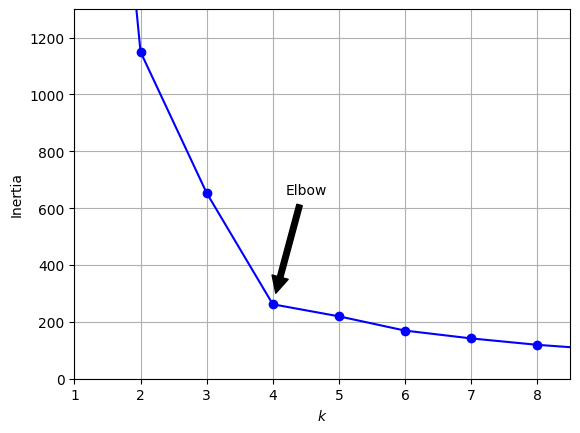

In [41]:
kmeans_per_k = [KMeans(n_clusters=i,n_init=10,random_state=42).fit(X) for i in range(1,10)]
inertias = [model.inertia_ for model in kmeans_per_k]
plt.plot(range(1,10),inertias,"bo-")
plt.xlabel("$k$")
plt.ylabel("Inertia")
plt.annotate("", xy=(4, inertias[3]), xytext=(4.45, 650),
             arrowprops=dict(facecolor='black', shrink=0.1))
plt.text(4.5, 650, "Elbow", horizontalalignment="center")
plt.axis([1, 8.5, 0, 1300])
plt.grid()
plt.show()

As you can see, there is an elbow at $k=4$, which means that less clusters than that would be bad, and more clusters would not help much and might cut clusters in half. So $k=4$ is a pretty good choice. Of course in this example it is not perfect since it means that the two blobs in the lower left will be considered as just a single cluster, but it's a pretty good clustering nonetheless.

Another approach is to look at the _silhouette score_, which is the mean _silhouette coefficient_ over all the instances.The silhouette coefficient can vary between -1 and +1: a coefficient close to +1 means that the instance is well inside its own cluster and far from other clusters, while a coefficient close to 0 means that it is close to a cluster boundary, and finally a coefficient close to -1 means that the instance may have been assigned to the wrong cluster.

In [45]:
from sklearn.metrics import silhouette_score

In [46]:
silhouette_score(X,kmeans.labels_)

0.655517642572828

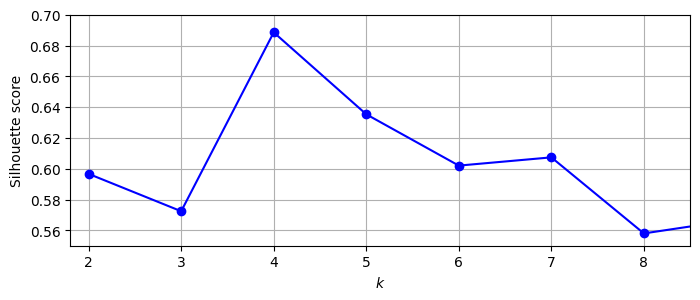

In [51]:
silhouette_scores = [silhouette_score(X,model.labels_) for model in kmeans_per_k[1:]]

plt.figure(figsize=(8, 3))
plt.plot(range(2,10),silhouette_scores,"bo-")
plt.xlabel("$k$")
plt.ylabel("Silhouette score")
plt.axis([1.8, 8.5, 0.55, 0.7])
plt.grid()
plt.show()

As you can see, this visualization is much richer than the previous one: in particular, although it confirms that $k=4$ is a very good choice

# Using Clustering for Image Segmentation

In [3]:
image = np.asarray(PIL.Image.open(Path("./images/ladybug.png")))
image.shape

(533, 800, 3)

height = 533 pixels
width  = 800 pixels
channels = 3 (RGB) \
so total pixels is 533 × 800 = 426,400 pixels. Each pixel has [R,G,B]

In [4]:
image[0]

array([[ 25,  29,   2],
       [ 24,  28,   1],
       [ 24,  29,   0],
       ...,
       [ 57, 105,  21],
       [ 56, 103,  22],
       [ 52,  99,  19]], shape=(800, 3), dtype=uint8)

In [6]:
# Reshape 
# K means expects samples x features
X = image.reshape(-1,3) # now it is 426400 × 3, each row = one pixel ,columns = R,G,B

In [7]:
# apply kmeans
kmeans = KMeans(n_clusters=8,n_init=10,random_state=42).fit(X) # Find 8 dominant colors in the image

In [8]:
kmeans.labels_

array([0, 0, 0, ..., 5, 5, 0], shape=(426400,), dtype=int32)

In [9]:
kmeans.cluster_centers_

array([[  5.6105612 ,  27.61743918,   1.44857047],
       [250.68280046, 237.8319458 ,   6.51237711],
       [ 54.37997208,  97.09151272,  14.07131629],
       [155.1122467 , 160.29920705,  98.37997063],
       [ 93.53208815, 132.47927103,  39.06947451],
       [ 24.39502109,  63.41611633,   4.09118396],
       [195.12454743,  50.81607531,  11.20057929],
       [223.40683449, 182.94424185,   9.39848253]])

In [10]:
kmeans.cluster_centers_[0]

array([ 5.6105612 , 27.61743918,  1.44857047])

In [11]:
# Now we replace each pixel color with the cluster center(cluster color).
# ex: Original pixel: [254, 5, 3], Cluster center: [230, 20, 20], Now pixel becomes:[230,20,20] . So similar colors collapse into one color.
segmented_image = kmeans.cluster_centers_[kmeans.labels_] 

In [12]:
# reshape back to image
segmented_image = segmented_image.reshape(image.shape)

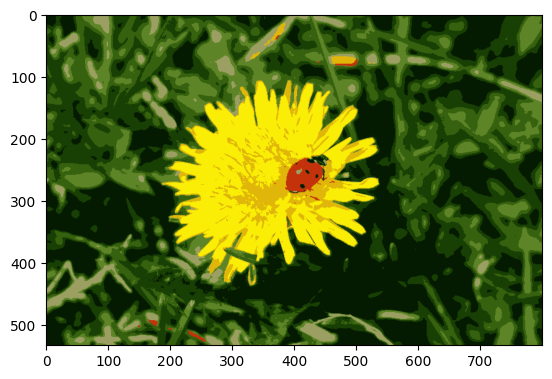

In [14]:
# befor millions of color variations , but now only 8 colors. So the image becomes simplified.
plt.imshow(segmented_image/255) # normalize 
plt.show()

The algorithm is not clustering pixels by position.It clusters only by: [R, G, B]

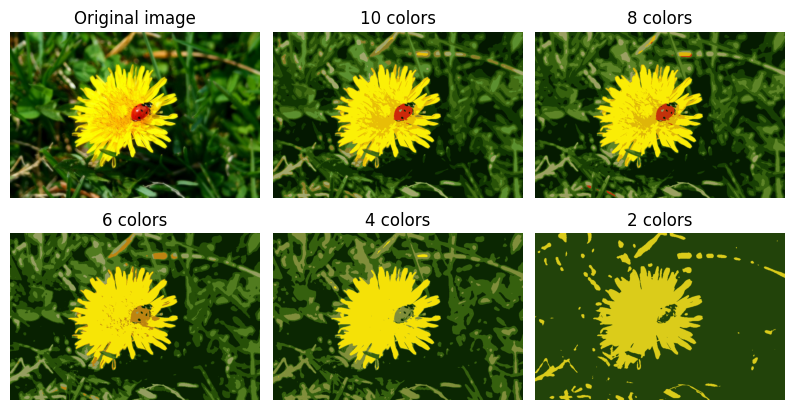

In [17]:
segmented_images = []
n_colores = (10, 8, 6, 4, 2)
for n_clusters in n_colores:
    kmeans = KMeans(n_clusters=n_clusters,n_init=10, random_state=42).fit(X)
    segmented_image = kmeans.cluster_centers_[kmeans.labels_]
    segmented_images.append(segmented_image.reshape(image.shape))
# PLot images
plt.figure(figsize=(10, 5))
plt.subplots_adjust(wspace=0.05, hspace=0.1)
# plot original image
plt.subplot(2,3,1)
plt.imshow(image)
plt.title("Original image")
plt.axis("off")
for idx, segmented_image in enumerate(segmented_images):
    plt.subplot(2,3,idx+2)
    plt.imshow(segmented_image/255)
    plt.title(f"{n_colores[idx]} colors")
    plt.axis("off")
plt.show()

# Using Clustering for Semi-Supervised Learning

In [2]:
from sklearn.datasets import load_digits
X_digits, y_digits = load_digits(return_X_y=True)
X_train, y_train = X_digits[:1400],y_digits[:1400]
X_test , y_test = X_digits[1400:],y_digits[1400:]

dataset containing 1,797 grayscale 8 × 8 images representing the digits 0 to 9 .\
Now take like You have 1,400 images of digits but only 50 are labeled.


In [3]:
# Base line, train with only 50 labeld image
from sklearn.linear_model import LogisticRegression

n_labeled = 50
log_reg = LogisticRegression().fit(X_train[:n_labeled],y_train[:n_labeled])

In [4]:
log_reg.score(X_test, y_test)

0.7581863979848866

score was not good. if we train with total data set we get around 0.90. Let's see how we can do better. First, let's cluster the training set into 50 clusters, then for each cluster let's find the image closest to the centroid. We will call these images the representative images:

In [5]:
k= 50
kmeans = KMeans(n_clusters=k,n_init=10, random_state=42)
# In KMeans class, the transform() method measures the distance from each instance to every centroid
X_digits_dist = kmeans.fit_transform(X_train) 

In [6]:
X_digits_dist

array([[39.2013243 , 51.61166593, 35.78092988, ..., 38.38114439,
        50.23366329, 39.12819457],
       [38.04484845, 32.68742517, 49.74639198, ..., 49.57935301,
        46.33618043, 40.98059968],
       [39.89248668, 41.45574598, 52.89107126, ..., 45.0884618 ,
        45.41881992, 38.78359351],
       ...,
       [47.70359228, 31.996892  , 53.95358402, ..., 51.32081966,
        58.66979688, 48.15773173],
       [46.20208562, 31.35143073, 53.34513581, ..., 51.42509909,
        58.40766568, 47.54535798],
       [35.79679446, 44.83906598, 47.16070489, ..., 47.4428765 ,
        54.8295814 , 39.67310178]], shape=(1400, 50))

In [7]:
X_digits_dist.shape

(1400, 50)

In [8]:
# For each cluster we choose the closest image to the center. so, we take minimum distance. 
representative_digit_idx = np.argmin(X_digits_dist,axis=0)
representative_digit_idx

array([ 816,  410, 1188,  468,  533,  692,  259,  877, 1178, 1309,  175,
        708, 1387,  932,  310,  991, 1312, 1250, 1005, 1114,  885, 1222,
        411,  543,  579,  141,  252, 1156, 1291,  870, 1168, 1050, 1383,
        959,  159,  881,  587,  251,  438,  520, 1198,  685,  983, 1295,
          2,  196, 1352,  908, 1159,  943])

In [9]:
X_representative_digits = X_train[representative_digit_idx]

Now let's plot these representative images and label them manually:

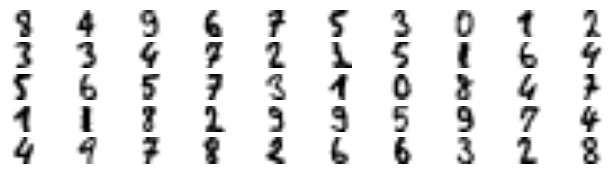

In [10]:
plt.figure(figsize=(8, 2))
for index, X_representative_digit in enumerate(X_representative_digits):
    plt.subplot(k // 10, 10, index + 1)
    plt.imshow(X_representative_digit.reshape(8, 8), cmap="binary",
               interpolation="bilinear")
    plt.axis('off')
plt.show()

In [11]:
y_representative_digits = np.array([
     8, 4, 9, 6, 7, 5, 3, 0, 1, 2,
     3, 3, 4, 7, 2, 1, 5, 1, 6, 4,
     5, 6, 5, 7, 3, 1, 0, 8, 4, 7, 
     1, 1, 8, 2, 9, 9, 5, 9, 7, 4, 
     4, 9, 7, 8, 2, 6, 6, 3, 2, 8
])

Now we have a dataset with just 50 labeled instances, but instead of being completely random instances, each of them is a representative image of its cluster. Let's see if the performance is any better:

In [12]:
log_reg = LogisticRegression(max_iter=10_000)
log_reg.fit(X_representative_digits, y_representative_digits)
log_reg.score(X_test, y_test)

0.8387909319899244

### Label Propagation 
All images in the same cluster probably belong to the same class.So we propagate the label.Cluster contains:3, 3, 3, 3, 3 Representative labeled as:3. Then all images in that cluster get label 3.

In [15]:
y_train_propagated = np.empty(len(X_train), dtype=np.int64)
for i in range(k):
    y_train_propagated[kmeans.labels_==i] = y_representative_digits[i] # set cluster i to i th representative digit. 

In [14]:
kmeans.labels_ ==0

array([False, False, False, ..., False, False, False], shape=(1400,))

In [16]:
log_reg = LogisticRegression(max_iter=10_000)
log_reg.fit(X_train,y_train_propagated )
log_reg.score(X_test,y_test)

0.8589420654911839

### Remove Outliers

In [18]:
np.arange(1,10)

array([1, 2, 3, 4, 5, 6, 7, 8, 9])

In [26]:
X_digits_dist[np.arange(len(X_train)),kmeans.labels_]
# X_digits_dist[[1,2,3],[0,1,2]]

array([10.76074391, 18.3067067 , 17.62961145, ..., 22.78107363,
       21.46025473, 17.25897512], shape=(1400,))

In [27]:
X_cluster_dist = X_digits_dist[np.arange(len(X_train)),kmeans.labels_] # every sample distance from it's cluster only


array([[39.2013243 , 51.61166593, 35.78092988, ..., 38.38114439,
        50.23366329, 39.12819457],
       [38.04484845, 32.68742517, 49.74639198, ..., 49.57935301,
        46.33618043, 40.98059968],
       [39.89248668, 41.45574598, 52.89107126, ..., 45.0884618 ,
        45.41881992, 38.78359351],
       ...,
       [47.70359228, 31.996892  , 53.95358402, ..., 51.32081966,
        58.66979688, 48.15773173],
       [46.20208562, 31.35143073, 53.34513581, ..., 51.42509909,
        58.40766568, 47.54535798],
       [35.79679446, 44.83906598, 47.16070489, ..., 47.4428765 ,
        54.8295814 , 39.67310178]], shape=(1400, 50))

In [28]:
X_digits_dist[np.arange(len(X_train))]

array([[39.2013243 , 51.61166593, 35.78092988, ..., 38.38114439,
        50.23366329, 39.12819457],
       [38.04484845, 32.68742517, 49.74639198, ..., 49.57935301,
        46.33618043, 40.98059968],
       [39.89248668, 41.45574598, 52.89107126, ..., 45.0884618 ,
        45.41881992, 38.78359351],
       ...,
       [47.70359228, 31.996892  , 53.95358402, ..., 51.32081966,
        58.66979688, 48.15773173],
       [46.20208562, 31.35143073, 53.34513581, ..., 51.42509909,
        58.40766568, 47.54535798],
       [35.79679446, 44.83906598, 47.16070489, ..., 47.4428765 ,
        54.8295814 , 39.67310178]], shape=(1400, 50))